# CAP182 SS3 - STADIOcare

### Tshegofatso Mogomotsi 26304837

**Background:** During SS2, Logistic Regression was identified as the model that performed the best for predicting 30-day hospital readmissions after outperforming the Random Forest model. The purpose of this notebook is to apply the selected Logistic Regression model to the datasets provided by STADIOcare in order to determine whether the model can successfully identify patients at risk of readmission within 30 days of discharge.

The STADIOcare provided admissions, demographic, clinical, medication, follow-up, claims and procedure data to support the prediction process.

The business objective is to assist STADIOcare with identifying patients at high risk of 30-day readmission.  
This will help with:  
        -Supporting discharge planning decisions.  
        -Prioritising follow-up interventions for high-risk patients.  
        -Reducing avoidable readmissions.  
        -and improving operational efficiency through proactive patient management.  



## Dataset loading

In [131]:
import pandas as pd
import numpy as np

The client supplied multiple datasets containing hospital admissions, patient demographics, clinical information, medication records, outpatient follow-up activity, claims information and procedure data.

***(See provided md file: Client_dataset_SS3.md)***

In [132]:
admissions = pd.read_csv("request1_admissions_discharge.csv")
demographics = pd.read_csv("request2_patient_demographics.csv")
clinical = pd.read_csv("request3_medical_history_clinical.csv")
medications = pd.read_csv("request4_medication_treatment.csv")
followup = pd.read_csv("request5_followup_outpatient.csv")
claims = pd.read_csv("request6_claims_billing.csv")
procedures = pd.read_csv("request7_procedures.csv")

print("Admissions:", admissions.shape)
print("Demographics:", demographics.shape)
print("Clinical:", clinical.shape)
print("Medications:", medications.shape)
print("Follow-up:", followup.shape)
print("Claims:", claims.shape)
print("Procedures:", procedures.shape)

print("\nTarget Distribution")
print(admissions["Readmitted_30_Days"].value_counts())

print("\nTarget Percentage")
print(
    admissions["Readmitted_30_Days"]
    .value_counts(normalize=True)
    * 100
)

Admissions: (9174, 13)
Demographics: (5218, 7)
Clinical: (5218, 10)
Medications: (32989, 6)
Follow-up: (4775, 6)
Claims: (9147, 14)
Procedures: (5689, 7)

Target Distribution
Readmitted_30_Days
No     8181
Yes     993
Name: count, dtype: int64

Target Percentage
Readmitted_30_Days
No     89.175932
Yes    10.824068
Name: proportion, dtype: float64


**Interpretation:** The target variable is highly imbalanced with 89.18% of admissions resulting in no readmission and only 10.82% resulting in a readmission within 30 days. This shows that readmission events are rare and require special consideration during model training to make sure that the high risk patients are not overlooked.

## Dataset processing

This part improves data quality and create a single admission level dataset that is suitable for the machine learning model.

-The following preprocessing steps were applied:

Duplicate removal
Standardisation of categorical values
Missing value treatment
Outlier handling
Aggregation of one-to-many datasets
Dataset merging
Class imbalance assessment
Train, validation and test splitting
Missing Values
Missing numerical values are replaced using the median because the median is less sensitive to outliers than the mean.

-Missing categorical values are replaced using "Unknown".

-Outliers
Extreme BMI values were identified and replaced with missing values before imputation because values below 10 or above 80 are medically unrealistic.

-Class imbalance
Class imbalance was assessed because readmission datasets are commonly imbalanced. This influenced the decision to use class weighting during model training.

-Aggregation
Medication, follow-up, claims and procedure datasets contain multiple records per admission.
These tables were aggregated to admission level before merging to create a single row per admission suitable for machine learning and to prevent duplicate records.

In [133]:
#__________________________________________REMOVE DUPLICATES


demographics = demographics.drop_duplicates()
clinical = clinical.drop_duplicates()


In [134]:
#_________________________________________STANDARDISE TEXT VALUES


demographics["Gender"] = (
    demographics["Gender"]
    .astype(str)
    .str.strip()
    .str.title()
)

clinical["Smoking_Status"] = (
    clinical["Smoking_Status"]
    .astype(str)
    .str.strip()
    .str.title()
)


In [135]:
#___________________________________________CLEAN TEXT


def clean_text(series):
    return (
        series.astype(str)
        .str.strip()
        .str.upper()
        .str.replace(r"\s+", " ", regex=True)
    )

# Demographics

demographics["Gender"] = (
    demographics["Gender"]
    .astype(str)
    .str.strip()
    .str.title()
)

demographics["Membership_Type"] = clean_text(
    demographics["Membership_Type"]
)

demographics["Employment_Status"] = clean_text(
    demographics["Employment_Status"]
)

demographics["Medical_Scheme"] = clean_text(
    demographics["Medical_Scheme"]
)

demographics["Province"] = clean_text(
    demographics["Province"]
)

# Clinical

clinical["Smoking_Status"] = clean_text(
    clinical["Smoking_Status"]
)

# Admissions

admissions["Admission_Type"] = clean_text(
    admissions["Admission_Type"]
)

admissions["Ward_Type"] = clean_text(
    admissions["Ward_Type"]
)

admissions["Discharge_Status"] = clean_text(
    admissions["Discharge_Status"]
)


In [136]:
#__________________________________________________HANDLE BMI OUTLIERS

clinical.loc[
    (clinical["BMI"] < 10) |
    (clinical["BMI"] > 80),
    "BMI"
] = np.nan


In [137]:
#_________________________________________________MEDICATION AGGREGATION

med_agg = (
    medications
    .groupby("Admission_ID")
    .agg(
        Medication_Count=("Medication_Name", "count"),
        Average_Daily_Dosage=("Daily_Dosage", "mean"),
        Number_of_Medications=("Number_of_Medications", "max"),
        Treatment_Completed=("Treatment_Completed", "max"),
        Follow_Up_Required=("Follow_Up_Required", "max")
    )
    .reset_index()
)


In [138]:
#________________________________________________FOLLOW-UP AGGREGATION

followup_agg = (
    followup
    .groupby("Admission_ID")
    .agg(
        Attended=("Attended", "max"),
        Days_to_Follow_Up=("Days_to_Follow_Up", "mean"),
        Missed_Appointments=("Missed_Appointments", "max")
    )
    .reset_index()
)



In [139]:
#_________________________________________________CLAIMS AGGREGATION

claims_agg = (
    claims
    .groupby("Admission_ID")
    .agg(
        Total_Claim_Value=("Total_Claim_Value", "sum"),
        Patient_Copayment=("Patient_Copayment", "sum"),
        Total_Line_Items=("Total_Line_Items", "sum"),
        Settlement_Amount=("Settlement_Amount", "sum"),
        Query_Flag=("Query_Flag", "max")
    )
    .reset_index()
)



In [140]:
#________________________________________________PROCEDURE AGGREGATION

procedure_agg = (
    procedures
    .groupby("Admission_ID")
    .agg(
        Procedure_Count=("Procedure_Code", "count"),
        Total_Theatre_Time=("Theatre_Time_Minutes", "sum")
    )
    .reset_index()
)



In [141]:
# _______________________________________________MERGE ALL DATASETS


df = admissions.merge(
    demographics,
    on="Patient_ID",
    how="left"
)

df = df.merge(
    clinical,
    on="Patient_ID",
    how="left"
)

df = df.merge(
    med_agg,
    on="Admission_ID",
    how="left"
)

df = df.merge(
    followup_agg,
    on="Admission_ID",
    how="left"
)

df = df.merge(
    claims_agg,
    on="Admission_ID",
    how="left"
)

df = df.merge(
    procedure_agg,
    on="Admission_ID",
    how="left"
)

In [142]:

#____________________________________________DATE FEATURES


df["Admission_Date"] = pd.to_datetime(
    df["Admission_Date"],
    errors="coerce"
)

df["Discharge_Date"] = pd.to_datetime(
    df["Discharge_Date"],
    errors="coerce"
)

df["Admission_Month"] = (
    df["Admission_Date"]
    .dt.month
)

df["Admission_DayOfWeek"] = (
    df["Admission_Date"]
    .dt.dayofweek
)

df["Weekend_Admission"] = (
    df["Admission_DayOfWeek"] >= 5
).astype(int)



In [143]:
# _____________________________Filling dates using forward strategy

df["Admission_Date"] = (
    df["Admission_Date"]
    .fillna(df["Admission_Date"].mode()[0])
)

df["Discharge_Date"] = (
    df["Discharge_Date"]
    .fillna(df["Discharge_Date"].mode()[0])
)

In [144]:
# ______________________________HANDLING MISSING VALUES


numeric_cols = df.select_dtypes(
    include=np.number
).columns

for col in numeric_cols:
    df[col] = df[col].fillna(
        df[col].median()
    )

categorical_cols = df.select_dtypes(
    include=["object", "string"]
).columns

for col in categorical_cols:
    df[col] = df[col].fillna(
        "Unknown"
    )

In [145]:
# _______________________________________TARGET ENCODING


df["Readmitted_30_Days"] = (
    df["Readmitted_30_Days"]
    .astype(str)
    .str.strip()
    .map({
        "No": 0,
        "Yes": 1
    })
)


In [146]:

#____________________________________________DUPLICATE REMOVAL


duplicates_before = df.duplicated().sum()

print(
    f"Duplicates Before Removal: {duplicates_before}"
)

df = df.drop_duplicates()

duplicates_after = df.duplicated().sum()

print(
    f"Duplicates After Removal: {duplicates_after}"
)

print(
    f"Dataset Shape After Duplicate Removal: {df.shape}"
)


Duplicates Before Removal: 27
Duplicates After Removal: 0
Dataset Shape After Duplicate Removal: (9147, 46)


In [147]:
#______________________________________________ DATA QUALITY CHECKS


print("Final Dataset Shape:", df.shape)

print("\nMissing Values")
print(df.isnull().sum())

print("\nDuplicate Rows")
print(df.duplicated().sum())

print("\nClass Distribution")
print(df["Readmitted_30_Days"].value_counts())

print("\nClass Percentage")
print(
    df["Readmitted_30_Days"]
    .value_counts(normalize=True)
    * 100
)

Final Dataset Shape: (9147, 46)

Missing Values
Patient_ID                      0
Admission_ID                    0
Admission_Date                  0
Discharge_Date                  0
Length_of_Stay                  0
Hospital_ID                     0
Ward_Type                       0
Admission_Type                  0
Procedure_Code                  0
Procedure_Description           0
Discharge_Status                0
Previous_Admissions             0
Readmitted_30_Days              0
Age                             0
Gender                          0
Province                        0
Medical_Scheme                  0
Membership_Type                 0
Employment_Status               0
Chronic_Diabetes                0
Chronic_Hypertension            0
Chronic_Heart_Disease           0
Chronic_Asthma                  0
Number_of_Chronic_Conditions    0
BMI                             0
Smoking_Status                  0
Allergies                       0
Risk_Score                      0


## Feature engineering

In [148]:


df["High_Utilisation_Patient"] = (
    df["Previous_Admissions"] >= 3
).astype(int)

df["High_Risk_Patient"] = (
    df["Risk_Score"] >= 7
).astype(int)

df["Missed_Followup_Flag"] = (
    df["Missed_Appointments"] > 0
).astype(int)

df["Claim_to_Copayment_Ratio"] = (
    df["Total_Claim_Value"] /
    (df["Patient_Copayment"] + 1)
)

df["Complex_Procedure"] = (
    df["Procedure_Count"] >= 2
).astype(int)

In [149]:
df.to_csv(
    "model_dataset.csv",
    index=False
)

print(
    "Model dataset saved successfully"
)

Model dataset saved successfully


## Model training

Logistic Regression was selected because it was the best-performing model during SS2 and therefore became the final recommended model.

Using the same model ensures consistency between SS2 and SS3.

Hyperparameters
max_iter = 2000

A larger number of iterations ensures convergence during optimisation.

class_weight = "balanced"

This compensates for the class imbalance identified during preprocessing.

random_state = 42

This ensures reproducibility.

Data Splitting
The dataset was divided into:

Training Set = 70%
Validation Set = 15%
Test Set = 15%
This allows model training, tuning and unbiased final evaluation.

In [150]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression

import joblib

In [151]:

#___________________________________VERIFY SAVED DATASET BEFORE MODELLING__________________


model_dataset = pd.read_csv(
    "model_dataset.csv"
)

print("\nModel Dataset Reloaded Successfully")

print(
    "\nShape:",
    model_dataset.shape
)

print(
    "\nColumns:"
)

print(
    model_dataset.columns.tolist()
)

print(
    "\nFirst Five Records:"
)

print(
    "\nTarget Distribution:"
)

print(
    model_dataset["Readmitted_30_Days"]
    .value_counts()
)

print(
    "\nTarget Percentage:"
)

print(
    model_dataset["Readmitted_30_Days"]
    .value_counts(normalize=True)
    * 100
)


Model Dataset Reloaded Successfully

Shape: (9147, 51)

Columns:
['Patient_ID', 'Admission_ID', 'Admission_Date', 'Discharge_Date', 'Length_of_Stay', 'Hospital_ID', 'Ward_Type', 'Admission_Type', 'Procedure_Code', 'Procedure_Description', 'Discharge_Status', 'Previous_Admissions', 'Readmitted_30_Days', 'Age', 'Gender', 'Province', 'Medical_Scheme', 'Membership_Type', 'Employment_Status', 'Chronic_Diabetes', 'Chronic_Hypertension', 'Chronic_Heart_Disease', 'Chronic_Asthma', 'Number_of_Chronic_Conditions', 'BMI', 'Smoking_Status', 'Allergies', 'Risk_Score', 'Medication_Count', 'Average_Daily_Dosage', 'Number_of_Medications', 'Treatment_Completed', 'Follow_Up_Required', 'Attended', 'Days_to_Follow_Up', 'Missed_Appointments', 'Total_Claim_Value', 'Patient_Copayment', 'Total_Line_Items', 'Settlement_Amount', 'Query_Flag', 'Procedure_Count', 'Total_Theatre_Time', 'Admission_Month', 'Admission_DayOfWeek', 'Weekend_Admission', 'High_Utilisation_Patient', 'High_Risk_Patient', 'Missed_Followup_

In [152]:

y = df["Readmitted_30_Days"]

X = df.drop(
    columns=[
        "Readmitted_30_Days",
        "Admission_ID",
        "Patient_ID",

        # remove raw timestamps
        "Admission_Date",
        "Discharge_Date",

        # high-cardinality text
        "Procedure_Description",
        "Procedure_Code"
    ],
    errors="ignore"
)

# 70 / 15 / 15 split

X_temp, X_test, y_temp, y_test = train_test_split(
    X,
    y,
    test_size=0.15,
    stratify=y,
    random_state=42
)

X_train, X_val, y_train, y_val = train_test_split(
    X_temp,
    y_temp,
    test_size=0.1765,
    stratify=y_temp,
    random_state=42
)

numeric_cols = X.select_dtypes(include=np.number).columns
categorical_cols = X.select_dtypes(exclude=np.number).columns

preprocessor = ColumnTransformer(
    [
        (
            "num",
            Pipeline(
                [
                    ("imputer", SimpleImputer(strategy="median")),
                    ("scaler", StandardScaler())
                ]
            ),
            numeric_cols
        ),
        (
            "cat",
            Pipeline(
                [
                    ("imputer", SimpleImputer(strategy="most_frequent")),
                    ("encoder", OneHotEncoder(handle_unknown="ignore"))
                ]
            ),
            categorical_cols
        )
    ])

model = Pipeline(
    [
        ("preprocessor", preprocessor),
        (
            "classifier",
            LogisticRegression(
                max_iter=2000,
                class_weight="balanced",
                random_state=42
            )
        )
    ])

model.fit(
    X_train,
    y_train)

joblib.dump(
    model,
    "logistic_regression_model.pkl")

print("Model training is complete")

Model training is complete


The target variable is highly imbalanced, with 89.18% of admissions not resulting in readmission and only 10.82% resulting in readmission.

To prevent the model from favouring the majority class, class_weight='balanced' was used so that readmission cases receive greater importance during training.

In [153]:
feature_names = (
    model.named_steps["preprocessor"]
    .get_feature_names_out()
)

coefficients = (
    model.named_steps["classifier"]
    .coef_[0]
)

importance = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": coefficients
})

importance["Abs_Coefficient"] = (
    importance["Coefficient"]
    .abs()
)

importance = (
    importance
    .sort_values(
        "Abs_Coefficient",
        ascending=False
    )
)

print(
    importance[
        ["Feature", "Coefficient"]
    ].head(20)
)


                                          Feature  Coefficient
84                 cat__Discharge_Status_DECEASED    -3.201281
83   cat__Discharge_Status_AGAINST MEDICAL ADVICE     0.881403
44                        cat__Hospital_ID_JHB005    -0.727914
38                        cat__Hospital_ID_DBN004    -0.660017
34                        cat__Hospital_ID_CPT005     0.638723
43                        cat__Hospital_ID_JHB004    -0.616050
87                    cat__Discharge_Status_OTHER     0.612174
61                        cat__Hospital_ID_POL002     0.603599
41                        cat__Hospital_ID_JHB002     0.569047
86           cat__Discharge_Status_HOME WITH CARE     0.564090
88                 cat__Discharge_Status_TRANSFER     0.555035
45                        cat__Hospital_ID_KIM001     0.553944
110                   cat__Medical_Scheme_PROFMED    -0.531379
85                     cat__Discharge_Status_HOME     0.525939
159                             cat__Attended_Yes    -0

## Model validation

The final model is evaluated using previously unseen test data.

The metrics I've used are:

Accuracy
Precision
Recall
F1 Score
ROC-AUC
Recall is particularly important because the business objective is to identify patients at risk of readmission before discharge.

Failing to identify a high-risk patient may lead to increased costs, higher readmission rates and poorer patient outcomes.

In [154]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report
)

In [155]:

predictions = model.predict(X_test)
probabilities = model.predict_proba(X_test)[:, 1]

accuracy = accuracy_score(y_test, predictions)
precision = precision_score(y_test, predictions)
recall = recall_score(y_test, predictions)
f1 = f1_score(y_test, predictions)
roc_auc = roc_auc_score(y_test, probabilities)

print("Accuracy :", accuracy)
print("Precision:", precision)
print("Recall   :", recall)
print("F1 Score :", f1)
print("ROC AUC  :", roc_auc)

print("\nClassification Report")
print(classification_report(y_test, predictions))

results = pd.DataFrame({
    "actual": y_test,
    "prediction": predictions,
    "probability": probabilities
})

results.to_csv(
    "SS3_predictions.csv",
    index=False
)

Accuracy : 0.6656955571740714
Precision: 0.18106995884773663
Recall   : 0.5906040268456376
F1 Score : 0.27716535433070866
ROC AUC  : 0.7062990744396193

Classification Report
              precision    recall  f1-score   support

           0       0.93      0.67      0.78      1224
           1       0.18      0.59      0.28       149

    accuracy                           0.67      1373
   macro avg       0.56      0.63      0.53      1373
weighted avg       0.85      0.67      0.73      1373



## Results visualisation

Visualisations will communicate the results after evaluating model performance to both technical and business stakeholders.

Graphs make it easier to identify patterns, understand classification results and assess the final predictive capability. In other words, the visualisations help SHOW whether the model can reliably identify high-risk patients before discharge.

Visualisations that will be produced:
1. Readmission class distribution
This visualisation shows the distribution of patients who were readmitted within 30 days compared to those who were not readmitted.
The chart helps identify whether class imbalance exists within the dataset and provides context for evaluating model performance.

2. Confusion matrix
The confusion matrix summarises classification performance by displaying:

True Positives (correctly predicted readmissions)
True Negatives (correctly predicted non-readmissions)
False Positives
False Negatives
This visualisation provides a detailed view of prediction accuracy and helps identify the types of errors made by the model.

3. ROC Curve
The Receiver Operating Characteristic (ROC) Curve evaluates the model's ability to distinguish between patients who are likely to be readmitted and those who are not.

The Area Under the Curve (AUC) provides a single performance measure, where values closer to 1 indicate stronger predictive performance.

4. Performance Metrics Comparison
A bar chart is used to visualise the key evaluation metrics:

Accuracy
Precision
Recall
F1 Score
ROC-AUC
This allows stakeholders to quickly compare performance across multiple evaluation criteria.


In [156]:
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.metrics import (
    ConfusionMatrixDisplay,
    roc_curve)


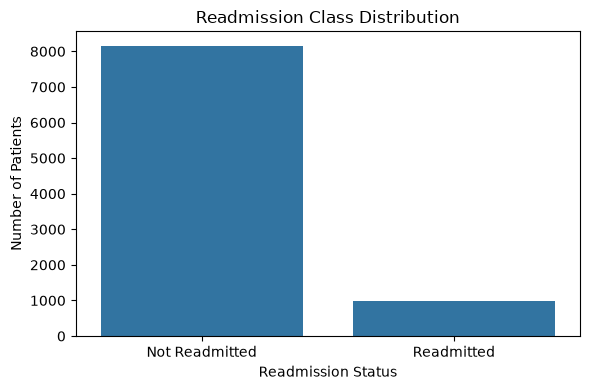

In [157]:
# ________________________________________CLASS DISTRIBUTION

plt.figure(figsize=(6, 4))

sns.countplot(
    data=df,
    x="Readmitted_30_Days")

plt.title("Readmission Class Distribution")
plt.xlabel("Readmission Status")
plt.ylabel("Number of Patients")

plt.xticks(
    ticks=[0, 1],
    labels=[
        "Not Readmitted",
        "Readmitted"
    ])

plt.tight_layout()

plt.savefig(
    "class_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


<Figure size 600x500 with 0 Axes>

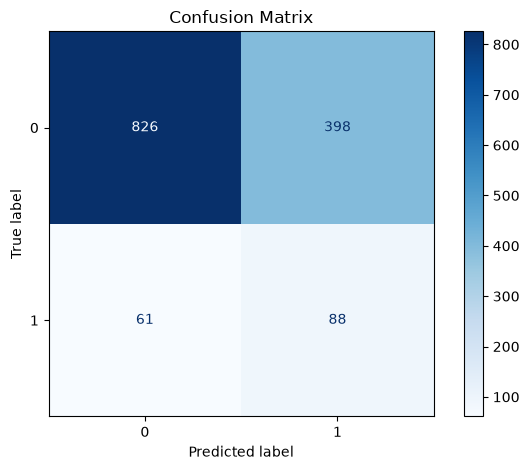

In [158]:
# _______________________________________ CONFUSION MATRIX

plt.figure(figsize=(6, 5))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    predictions,
    cmap="Blues")

plt.title("Confusion Matrix")

plt.tight_layout()

plt.savefig(
    "confusion_matrix.png",
    dpi=300,
    bbox_inches="tight")

plt.show()

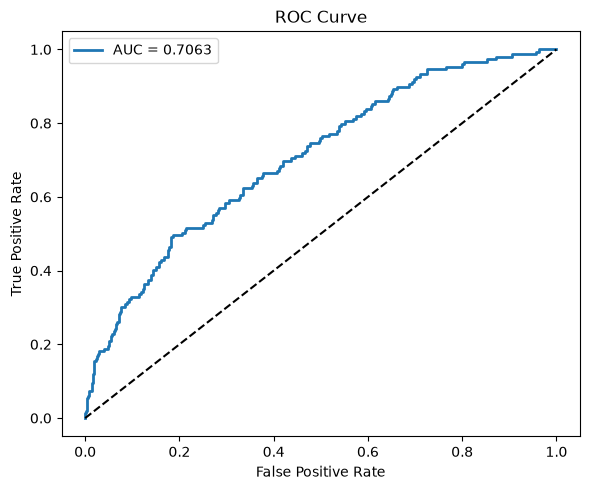

In [159]:
# ________________________________________ROC CURVE

fpr, tpr, _ = roc_curve(
    y_test,
    probabilities)

plt.figure(figsize=(6, 5))

plt.plot(
    fpr,
    tpr,
    linewidth=2,
    label=f"AUC = {roc_auc:.4f}")

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="black")

plt.title("ROC Curve")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()

plt.tight_layout()

plt.savefig(
    "roc_curve.png",
    dpi=300,
    bbox_inches="tight")

plt.show()

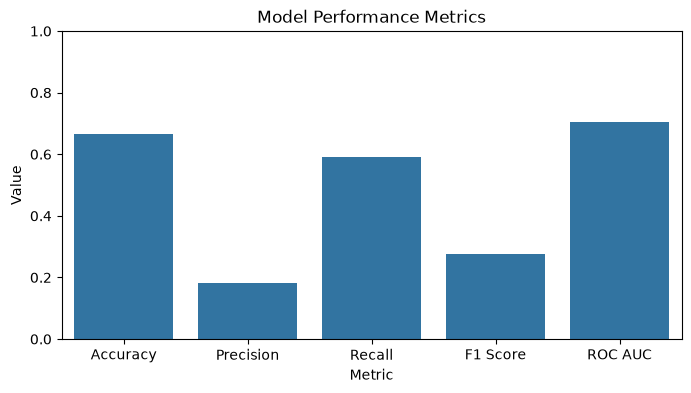

In [160]:
# _____________________________________METRICS VISUALISATION

metrics_df = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1 Score",
        "ROC AUC"
    ],
    "Value": [
        accuracy,
        precision,
        recall,
        f1,
        roc_auc
    ]
})

plt.figure(figsize=(8, 4))

sns.barplot(
    data=metrics_df,
    x="Metric",
    y="Value"
)

plt.title("Model Performance Metrics")
plt.ylim(0, 1)

for index, value in enumerate(metrics_df["Value"]):
    plt



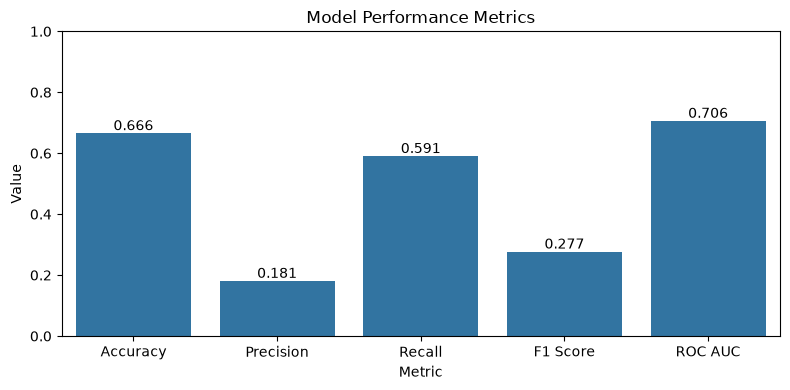

performance_metrics.png has been created


In [161]:
#_______________________________________MODEL PERFORMANCE METRIC

plt.figure(figsize=(8, 4))

sns.barplot(
    data=metrics_df,
    x="Metric",
    y="Value"
)

plt.title("Model Performance Metrics")
plt.ylim(0, 1)

for index, value in enumerate(metrics_df["Value"]):
    plt.text(
        index,
        value + 0.01,
        f"{value:.3f}",
        ha="center"
    )

plt.tight_layout()

plt.savefig(
    "performance_metrics.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("performance_metrics.png has been created")

## Additional: The graph below is only to support the literature review statements about my feature selection choices 

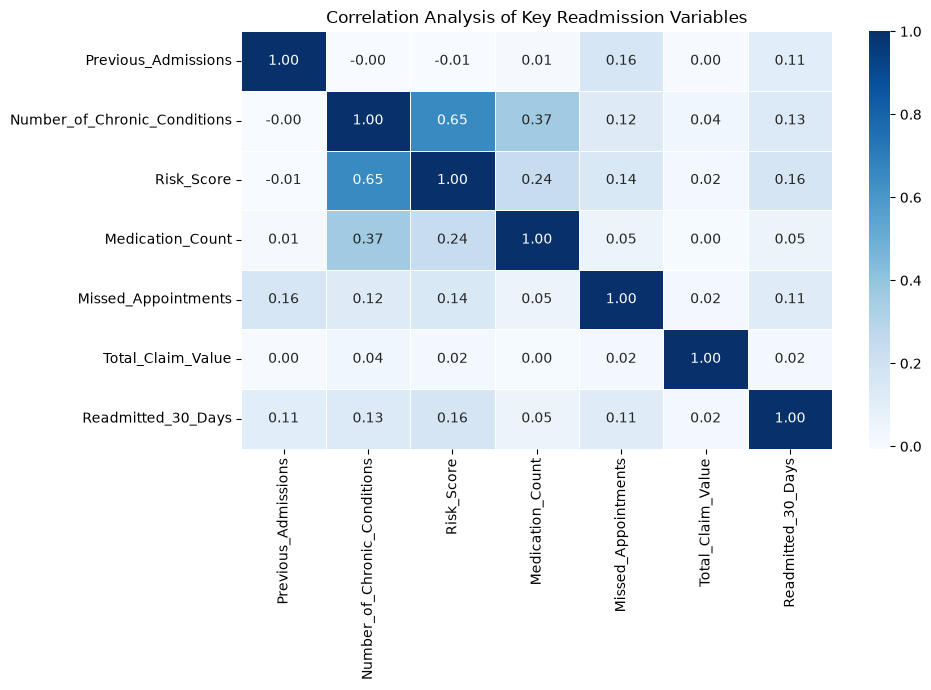

Created: literature_validation_correlation_heatmap.png


In [162]:
#________________________________________ CORRELATION ANALYSIS

correlation_features = [

    "Previous_Admissions",
    "Number_of_Chronic_Conditions",
    "Risk_Score",
    "Medication_Count",
    "Missed_Appointments",
    "Total_Claim_Value",
    "Readmitted_30_Days"

]

corr_matrix = (
    df[correlation_features]
    .corr()
)


# __________________________________________HEATMAP


plt.figure(figsize=(10, 7))

sns.heatmap(
    corr_matrix,
    annot=True,
    cmap="Blues",
    fmt=".2f",
    linewidths=0.5
)

plt.title(
    "Correlation Analysis of Key Readmission Variables"
)

plt.tight_layout()

plt.savefig(
    "literature_validation_correlation_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(
    "Created: literature_validation_correlation_heatmap.png"
)